# 02 · Member attendance EDA

**Synthetic selected public sample.** Descriptive volume, intervals, early attendance and context. The 32-member attendance cohort is selected from the export, not a representative population. Run scripts/analyze.py first.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src/data/load.py").exists(), "Run from the repository or notebooks directory"
sys.path.insert(0, str(ROOT))
from src.data.load import load_tables, audit_tables
from src.features.attendance import member_metrics
tables = load_tables(ROOT)
m, c = tables["members"], tables["checkins"]


In [2]:
counts = c.groupby("member_id").size()
display(counts.describe().to_frame("exported_events"))
for name in ["member_week", "member_month"]:
    panel = pd.read_csv(ROOT / f"data/processed/{name}.csv")
    print(name, "rows", len(panel), "zero-export share", panel.exported_events.eq(0).mean())
    display(panel.head())

,exported_events
count,32.000000
mean,62.500000
std,47.829671
min,4.000000
25%,20.750000
50%,55.000000
75%,89.500000
max,176.000000


member_week rows 1855 zero-export share 0.5234501347708895


,member_id,week,exported_events,calendar_opportunity_days,boundary_or_signup_partial,coverage_verified
0,1,2023-09-11/2023-09-17,0,5,True,False
1,1,2023-09-18/2023-09-24,3,7,False,False
2,1,2023-09-25/2023-10-01,1,7,False,False
3,1,2023-10-02/2023-10-08,1,7,False,False
4,1,2023-10-09/2023-10-15,4,7,False,False


member_month rows 439 zero-export share 0.36674259681093396


,member_id,month,exported_events,calendar_opportunity_days,boundary_or_signup_partial,coverage_verified
0,1,2023-09,4,18,True,False
1,1,2023-10,11,31,False,False
2,1,2023-11,16,30,False,False
3,1,2023-12,10,31,False,False
4,1,2024-01,7,31,False,False


In [3]:
for name in ["branch_summary", "plan_summary", "tenure_summary"]:
    print(name)
    display(pd.read_csv(ROOT / f"data/processed/{name}.csv"))
gaps = c.sort_values("checkin_datetime").groupby("member_id").checkin_datetime.diff().dt.total_seconds()/86400
display(gaps.describe().to_frame("days_between_exported_events"))

branch_summary


,visit_branch,events,members_with_events
0,IronFit Downtown,754,14
1,IronFit Eastside,575,7
2,IronFit Pearl District,671,11


plan_summary


,plan_name,events,members_with_events
0,Basic Annual,419,6
1,Basic Monthly,293,7
2,Premium Annual,392,5
3,Premium Monthly,763,12
4,Student,133,2


tenure_summary


,tenure_band,events,members_with_events
0,0–29,235,31
1,30–89,387,28
2,90–179,448,23
3,180–364,660,16
4,365+,270,8


,days_between_exported_events
count,1968.000000
mean,3.867671
std,4.871036
min,0.001389
25%,0.956944
50%,2.422917
75%,4.968403
max,67.204861


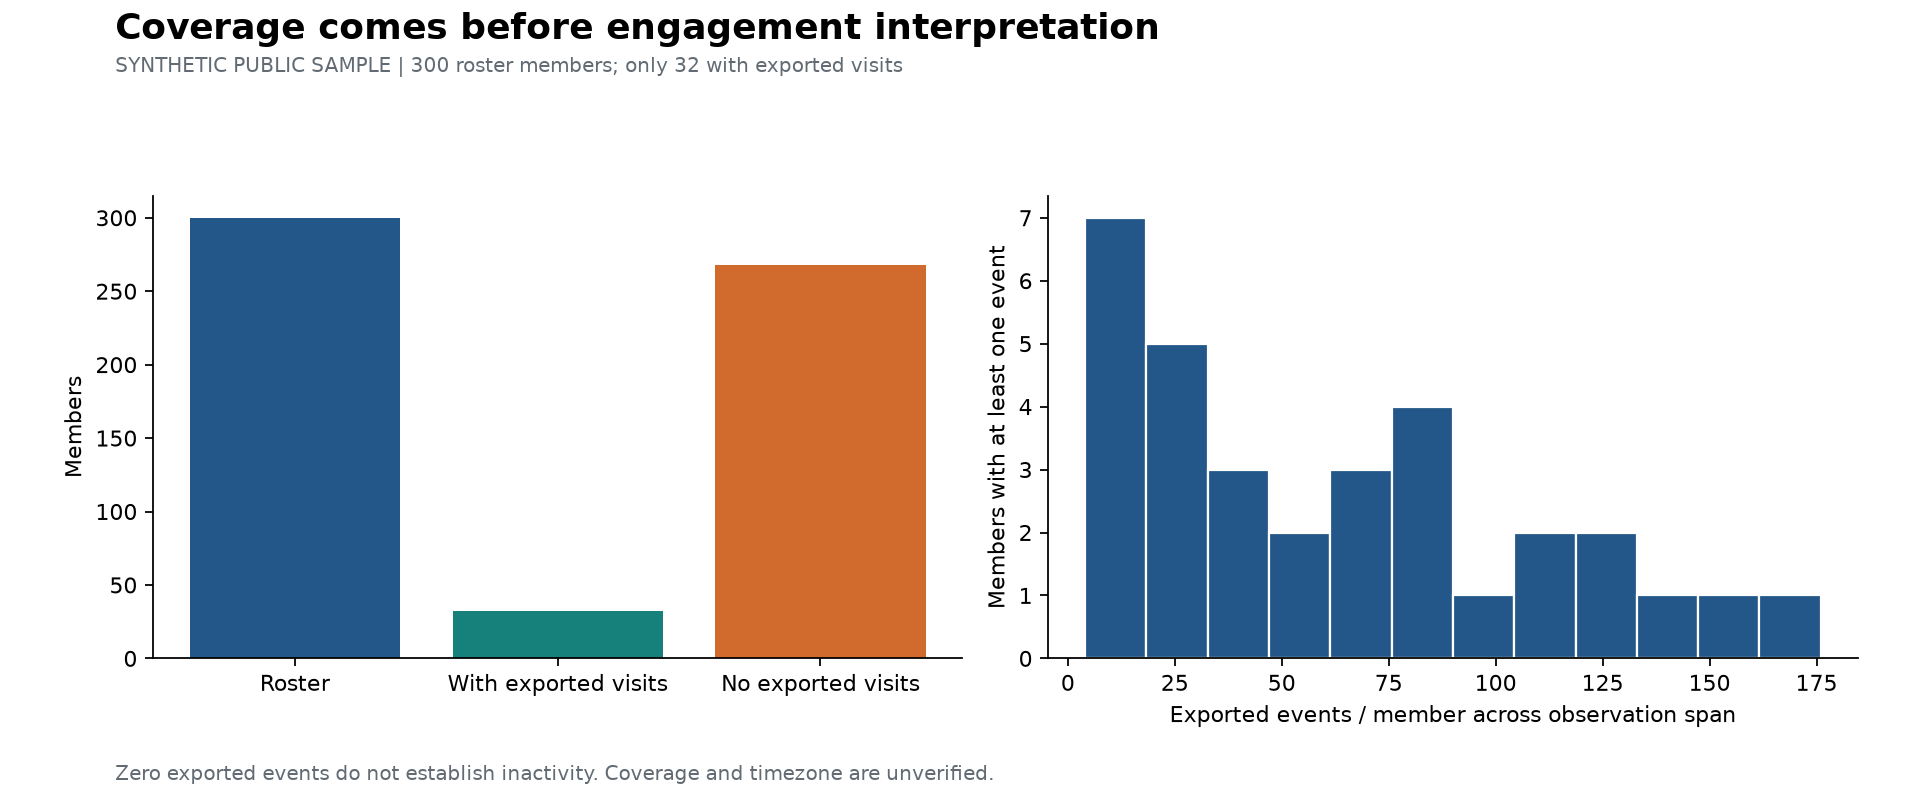

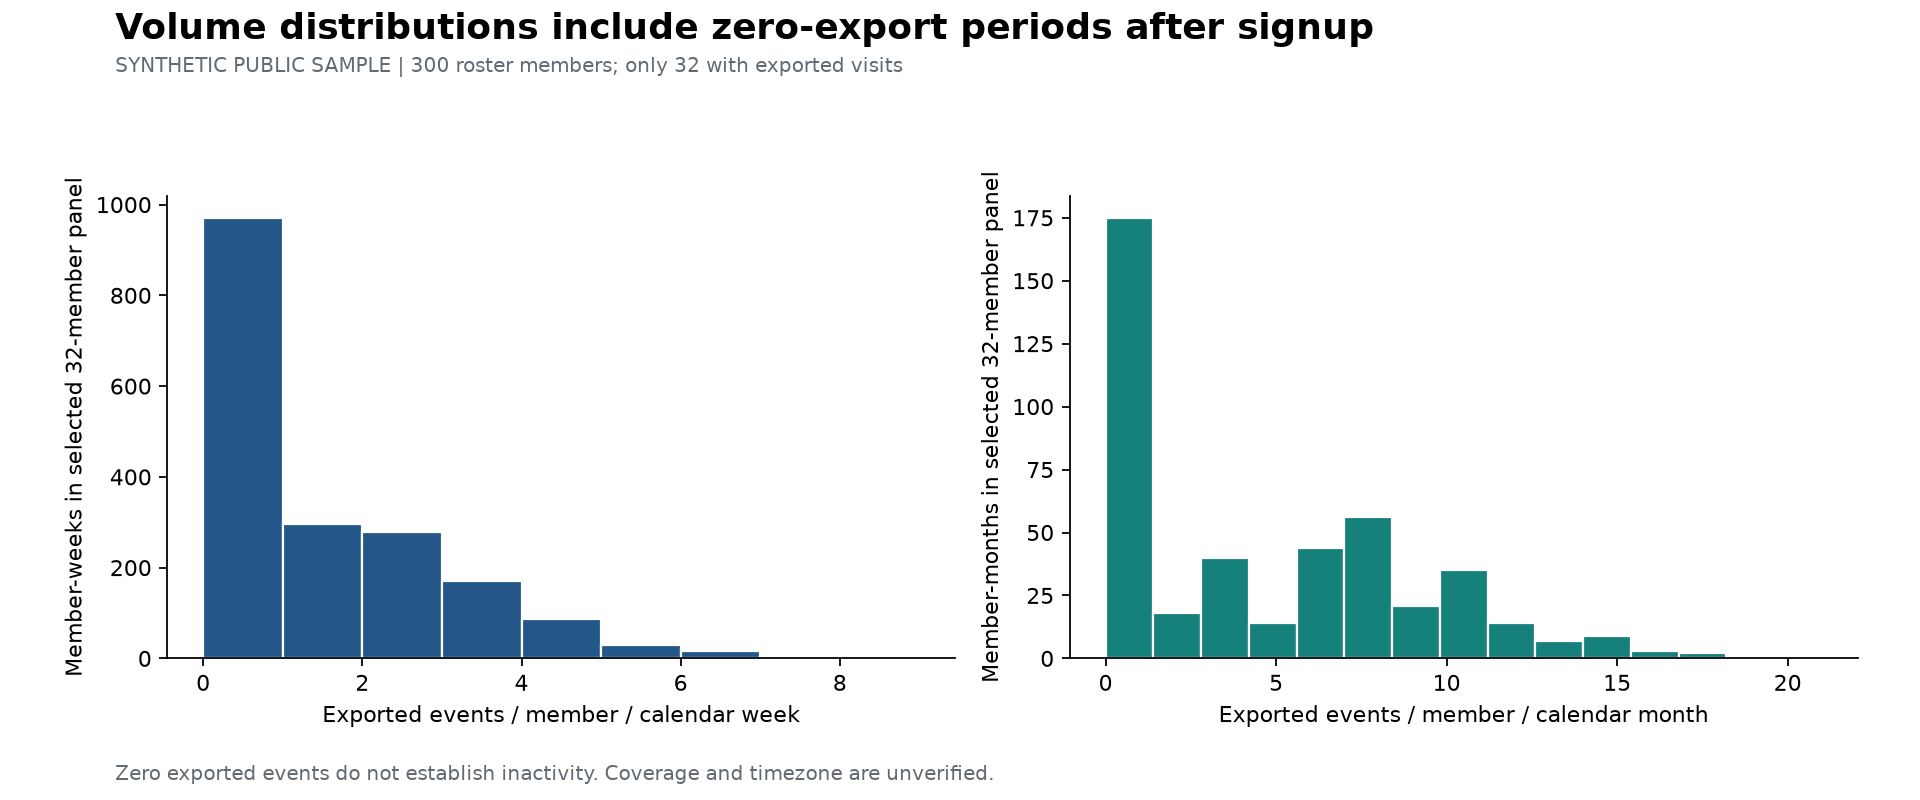

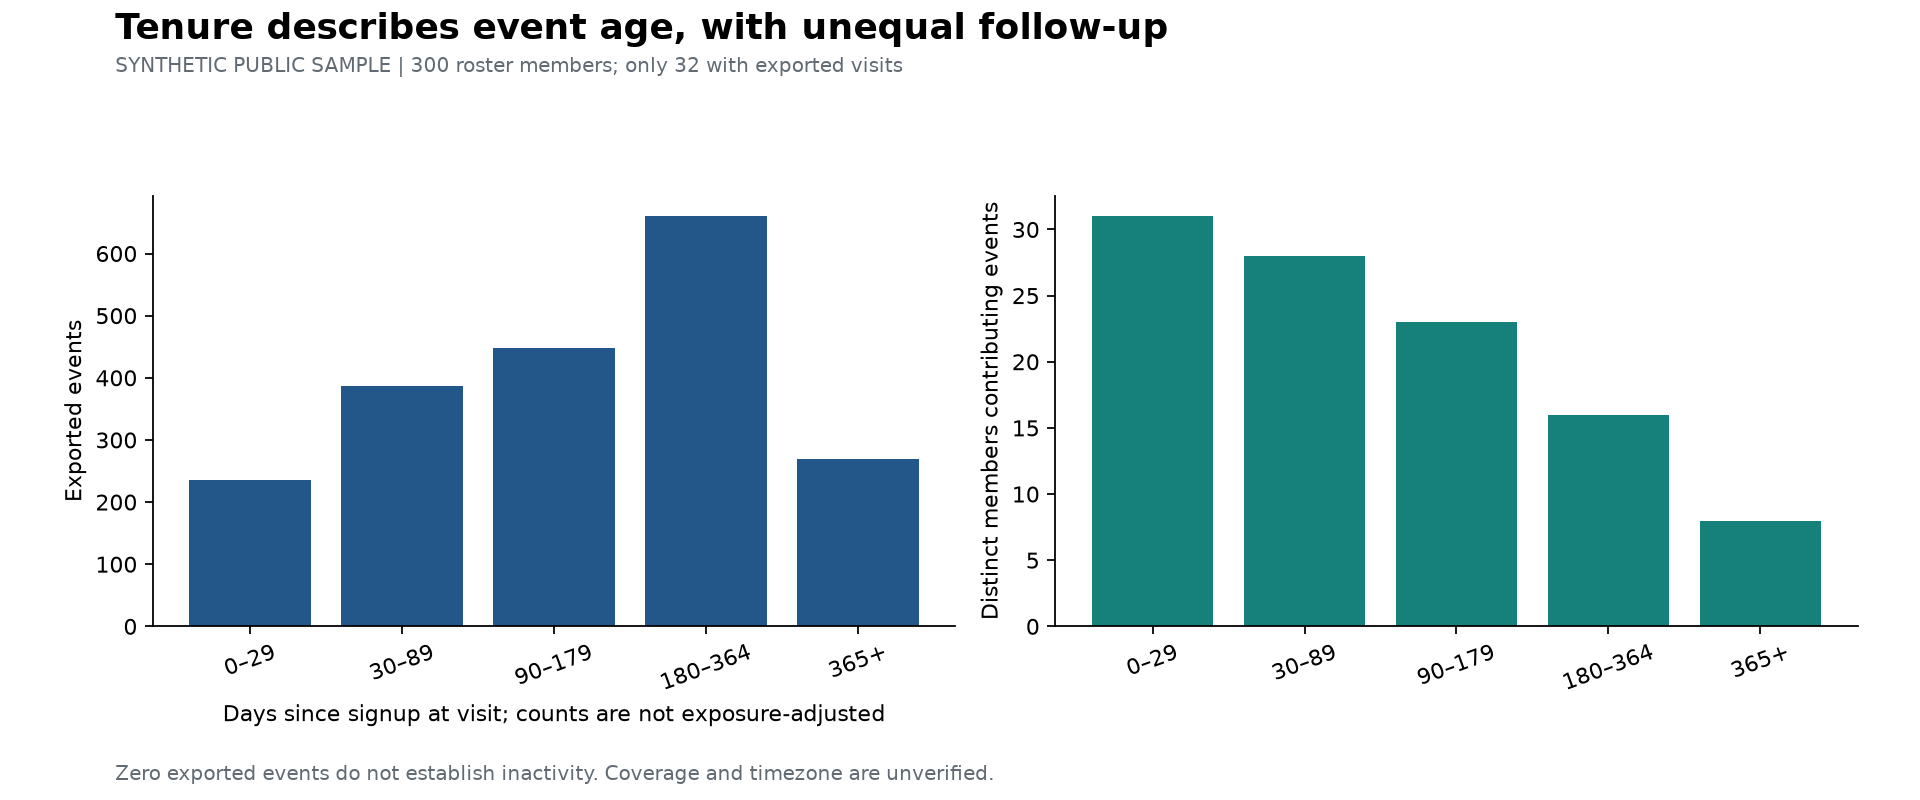

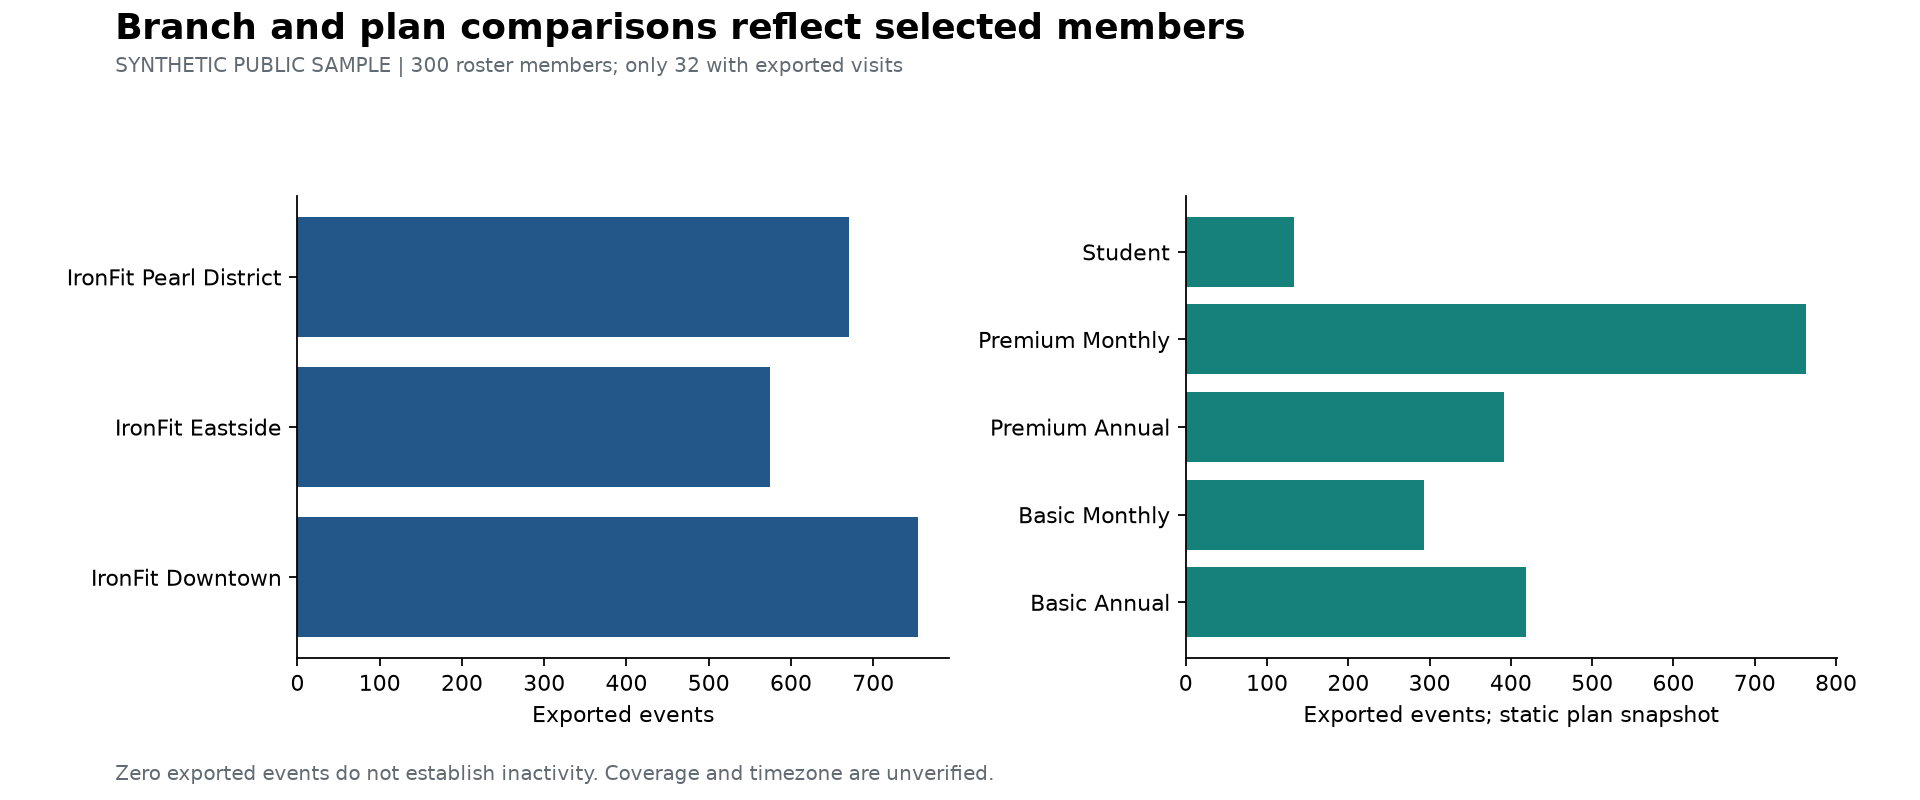

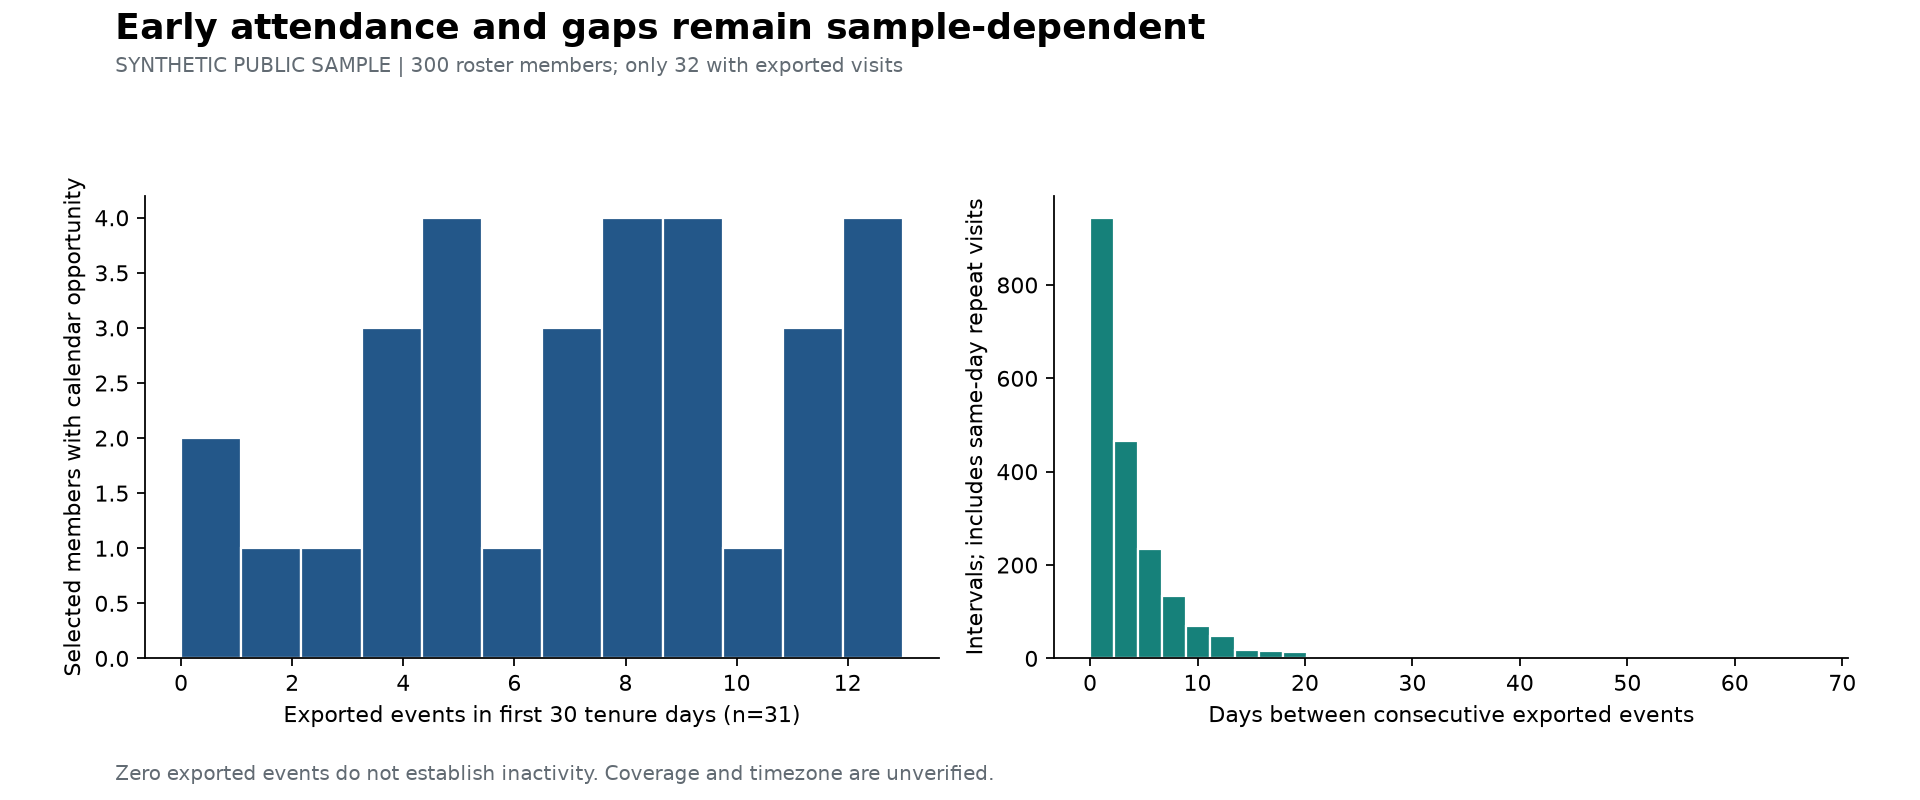

In [4]:
for name in ["01_coverage_and_volume", "03_week_month_distributions", "06_membership_tenure", "07_branch_and_plan", "11_early_behavior_and_gaps"]:
    display(Image(filename=str(ROOT / f"reports/figures/{name}.png")))

## Interpretation

Volume distributions include zero exported records after signup, including calendar time after available cancellation dates. Partial calendar periods are flagged. Neither those periods nor signup-derived opportunity establish entitlement or complete capture. Unequal tenure/follow-up and subgroup support prevent engagement rankings. Session gaps include same-day repeats and sampling uncertainty. Do not establish state thresholds from these descriptive bins.